In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import ast 

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

def clean_list(skills):
    if pd.notna(skills):
        return ast.literal_eval(skills)
    
df['job_skills'] = df['job_skills'].apply(clean_list)

In [3]:
df_anal = df[df['job_title_short'] == 'Data Analyst'].copy()

In [4]:
df_anal_exploded = df_anal.explode('job_skills')

In [5]:
df_anal_exploded['job_posted_month'] = df_anal_exploded['job_posted_date'].dt.month

In [6]:
anal_pivot =df_anal_exploded.pivot_table(
    index='job_posted_month',
    columns='job_skills',
    aggfunc='size'
)

anal_pivot.fillna(0, inplace=True)

job_skills,airflow,airtable,alteryx,angular,angular.js,ansible,apl,arch,asana,asp.net,...,webex,windows,wire,word,workfront,wrike,wsl,xamarin,yarn,zoom
job_posted_month,,,,,,,,,,,,,,,,,,,,,
1,197.0,17.0,551.0,63.0,2.0,20.0,2.0,1.0,29.0,34.0,...,17.0,228.0,6.0,1778.0,0.0,11.0,6.0,0.0,9.0,95.0
2,169.0,2.0,448.0,49.0,0.0,14.0,1.0,4.0,27.0,13.0,...,9.0,202.0,6.0,1235.0,4.0,2.0,5.0,0.0,4.0,41.0
3,181.0,4.0,442.0,34.0,0.0,23.0,6.0,1.0,17.0,13.0,...,8.0,194.0,8.0,1203.0,1.0,1.0,3.0,1.0,5.0,45.0
4,155.0,4.0,413.0,22.0,0.0,11.0,8.0,9.0,9.0,15.0,...,9.0,185.0,14.0,1177.0,8.0,2.0,1.0,0.0,6.0,26.0
5,128.0,8.0,310.0,30.0,0.0,19.0,9.0,2.0,8.0,21.0,...,11.0,122.0,3.0,957.0,3.0,4.0,0.0,0.0,7.0,18.0
6,164.0,14.0,393.0,29.0,0.0,14.0,9.0,4.0,16.0,16.0,...,8.0,157.0,14.0,1237.0,6.0,6.0,0.0,0.0,11.0,34.0
7,207.0,4.0,366.0,15.0,0.0,8.0,5.0,8.0,19.0,12.0,...,5.0,161.0,11.0,1069.0,0.0,3.0,0.0,0.0,6.0,38.0
8,197.0,3.0,413.0,21.0,0.0,12.0,10.0,3.0,13.0,12.0,...,9.0,184.0,11.0,1298.0,0.0,1.0,0.0,0.0,11.0,41.0
9,118.0,4.0,317.0,21.0,0.0,14.0,3.0,10.0,12.0,10.0,...,4.0,150.0,8.0,945.0,0.0,1.0,0.0,0.0,5.0,25.0


In [7]:
top_5_skills = anal_pivot.sum().sort_values(ascending=False).nlargest(5).index

In [8]:
anal_pivot.loc['Total'] = anal_pivot.sum()
anal_pivot = anal_pivot[anal_pivot.loc['Total'].sort_values(ascending=False).nlargest(5).index]
anal_pivot = anal_pivot.drop('Total')
anal_pivot

job_skills,sql,excel,python,tableau,power bi
job_posted_month,,,,,
1,11336.0,8170.0,6606.0,5596.0,4285.0
2,7947.0,5772.0,4751.0,3936.0,3307.0
3,7868.0,5675.0,4741.0,4051.0,3176.0
4,7553.0,5496.0,4557.0,3776.0,3106.0
5,6617.0,4773.0,4070.0,3245.0,2695.0
6,7584.0,5724.0,4707.0,3812.0,3275.0
7,7687.0,5513.0,4831.0,3928.0,3350.0
8,8823.0,6482.0,5576.0,4533.0,3859.0
9,6829.0,4886.0,4229.0,3446.0,3118.0


In [9]:
anal_pivot = anal_pivot.reset_index()

In [10]:
anal_pivot['month_posted'] = anal_pivot['job_posted_month'].apply(lambda x: pd.to_datetime(x, format='%m').strftime('%B'))

In [11]:
anal_pivot.set_index('month_posted', inplace=True)

In [12]:
anal_pivot.drop('job_posted_month', inplace=True, axis=1)

In [13]:
anal_pivot

job_skills,sql,excel,python,tableau,power bi
month_posted,,,,,
January,11336.0,8170.0,6606.0,5596.0,4285.0
February,7947.0,5772.0,4751.0,3936.0,3307.0
March,7868.0,5675.0,4741.0,4051.0,3176.0
April,7553.0,5496.0,4557.0,3776.0,3106.0
May,6617.0,4773.0,4070.0,3245.0,2695.0
June,7584.0,5724.0,4707.0,3812.0,3275.0
July,7687.0,5513.0,4831.0,3928.0,3350.0
August,8823.0,6482.0,5576.0,4533.0,3859.0
September,6829.0,4886.0,4229.0,3446.0,3118.0


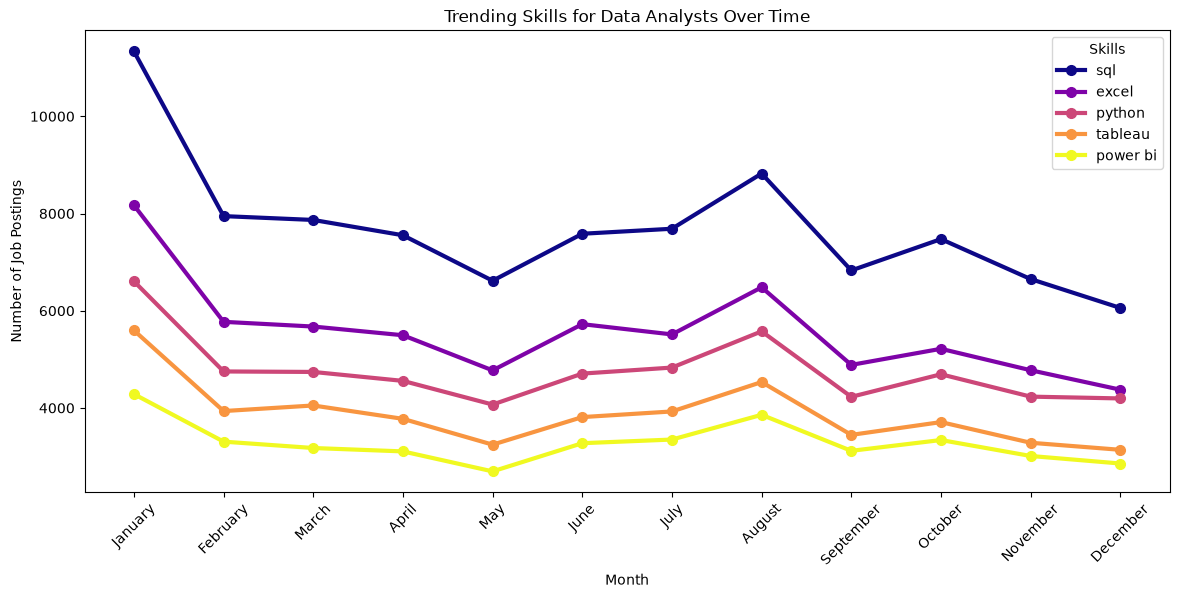

In [31]:
anal_pivot.plot(kind='line',
                linewidth=3,
                colormap='plasma',
                marker='o',
                markersize=7,
                figsize=(14, 6))
plt.title('Trending Skills for Data Analysts Over Time')
plt.xlabel('Month')
plt.xticks(
    ticks = range(len(anal_pivot.index)),
    labels = anal_pivot.index,
    rotation = 45
)
plt.ylabel('Number of Job Postings')
plt.legend(title='Skills')